# Activity 5 — Text Extraction

One photo holds several license plates side by side, so this detects each plate first, then runs the same character-extraction + OCR + color-classification pipeline on every one.

Imports, image file, and Tesseract setup.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import pytesseract
import shutil
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titleweight': 'bold'})

IMAGE_PATH = Path('license.png')
if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Could not find {IMAGE_PATH}")

# Tesseract: PATH, TESSERACT_CMD, or the default Windows install.
tesseract_cmd = os.environ.get('TESSERACT_CMD') or shutil.which('tesseract')
if not tesseract_cmd:
    windows_path = Path(os.environ.get('ProgramFiles', 'C:/Program Files')) / 'Tesseract-OCR/tesseract.exe'
    tesseract_cmd = str(windows_path) if windows_path.is_file() else None
if not tesseract_cmd:
    raise RuntimeError('Install Tesseract OCR, then add it to PATH or set TESSERACT_CMD.')
pytesseract.pytesseract.tesseract_cmd = tesseract_cmd

print(f"Tesseract {pytesseract.get_tesseract_version()} · {IMAGE_PATH.name}")


Tesseract 5.3.4 · license.png


Detect each plate in the photo. (Unlike a folder of separate plate images, this is one composite photo, so the first step is finding where each plate sits before anything else can run.)

In [2]:
def detect_plates(image):
    """Each plate is a solid block against the near-white page, so anything
    clearly darker than the page is a plate. Returns crops in reading order
    (left-to-right, top-to-bottom), each paired with its (x, y, w, h)."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 245, 255, cv2.THRESH_BINARY_INV)

    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    min_area = 0.01 * image.shape[0] * image.shape[1]
    boxes = [cv2.boundingRect(c) for c in contours if cv2.contourArea(c) >= min_area]

    # Group into rows (boxes whose y is close together), then sort each row left-to-right.
    boxes.sort(key=lambda b: b[1])
    row_tol = max(h for *_, h in boxes) * 0.5 if boxes else 0
    rows = []
    for box in boxes:
        for row in rows:
            if abs(row[0][1] - box[1]) < row_tol:
                row.append(box)
                break
        else:
            rows.append([box])
    rows.sort(key=lambda row: row[0][1])

    ordered = []
    for row in rows:
        row.sort(key=lambda b: b[0])
        ordered.extend(row)
    return [(image[y:y+h, x:x+w], (x, y, w, h)) for x, y, w, h in ordered]


Find the characters: crop, Otsu threshold, then keep tall, narrow contours (skips the plate border and the screw holes). `RETR_EXTERNAL` matters here — letters like P, D, 0, 9 have an enclosed loop, and `RETR_LIST` would also return that loop as its own tiny box.

In [3]:
def find_characters(plate):
    """Return the cropped plate, its binary mask, and the sorted character boxes."""
    height, width = plate.shape[:2]
    crop = plate[int(height*0.15):int(height*0.85), int(width*0.035):int(width*0.965)]

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (3, 3), 0)
    _, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if cv2.countNonZero(binary) < binary.size / 2:
        binary = cv2.bitwise_not(binary)  # make the background (majority) white

    contours, _ = cv2.findContours(255 - binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    ch, cw = crop.shape[:2]
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if ch * 0.35 <= h <= ch * 0.95 and cw * 0.02 <= w <= cw * 0.16:
            boxes.append((x, y, w, h))
    return crop, binary, sorted(boxes, key=lambda b: b[0])


Classify the plate: yellow background means Public Utility, otherwise the character ink color decides.

In [4]:
def classify_plate(crop, binary, boxes):
    """Return (category, background color name, character color name) from pixel colors."""
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    char_mask = np.zeros(binary.shape, np.uint8)
    for x, y, w, h in boxes:
        char_mask[y:y+h, x:x+w] = 255
    ink = hsv[(char_mask == 255) & (binary == 0)]   # character pixels
    paper = hsv[binary == 255]                        # plate background pixels
    bg_h, bg_s, _ = np.median(paper, axis=0)
    ink_h, ink_s, ink_v = np.median(ink, axis=0)

    if 15 <= bg_h <= 35 and bg_s > 100:
        return 'Public Utility', 'yellow', 'black'

    if ink_s < 50 or ink_v < 25:
        ink_name = 'black'
    elif ink_h < 10 or ink_h > 170:
        ink_name = 'red'
    elif 35 <= ink_h <= 90:
        ink_name = 'green'
    elif 95 <= ink_h <= 130:
        ink_name = 'blue'
    else:
        ink_name = 'unknown'

    category = {'red': 'Government', 'green': 'E-Vehicle', 'blue': 'Diplomatic',
                'black': 'Private'}.get(ink_name, 'Unknown')
    bg_name = 'white' if bg_s < 60 else 'colored'
    return category, bg_name, ink_name


Read the text: OCR each character several ways (sizes, padding, page-segmentation modes), take the majority vote, then split into letters and digits at the widest horizontal gap.

In [5]:
LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
DIGITS = '0123456789'

def read_character(binary, box, whitelist):
    """Vote across sizes, padding, and page-segmentation modes to stabilize one character."""
    x, y, w, h = box
    glyph = binary[y:y+h, x:x+w]
    votes = Counter()
    for size in (100, 140):
        resized = cv2.resize(glyph, None, fx=size / h, fy=size / h, interpolation=cv2.INTER_CUBIC)
        for pad in (20, 35):
            padded = cv2.copyMakeBorder(resized, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=255)
            _, padded = cv2.threshold(padded, 127, 255, cv2.THRESH_BINARY)
            for psm in (8, 10, 13):
                config = f'--psm {psm} -c tessedit_char_whitelist={whitelist}'
                text = pytesseract.image_to_string(padded, config=config).strip()
                if text and text[0] in whitelist:
                    votes[text[0]] += 1
    return votes.most_common(1)[0][0] if votes else '?'


def read_plate(binary, boxes):
    """Letters come before the widest gap, digits after it."""
    gaps = [boxes[i + 1][0] - (boxes[i][0] + boxes[i][2]) for i in range(len(boxes) - 1)]
    split = int(np.argmax(gaps)) + 1
    letters = ''.join(read_character(binary, b, LETTERS) for b in boxes[:split])
    digits = ''.join(read_character(binary, b, DIGITS) for b in boxes[split:])
    return f'{letters} {digits}'


def character_strip(binary, boxes):
    """Selected characters only, on white paper, for display."""
    clean = np.full_like(binary, 255)
    for x, y, w, h in boxes:
        clean[y:y+h, x:x+w] = binary[y:y+h, x:x+w]
    left, right = min(b[0] for b in boxes), max(b[0] + b[2] for b in boxes)
    top, bottom = min(b[1] for b in boxes), max(b[1] + b[3] for b in boxes)
    return cv2.copyMakeBorder(clean[top:bottom, left:right], 20, 20, 20, 20,
                               cv2.BORDER_CONSTANT, value=255)


def recognize_plate(image, box, index):
    crop, binary, boxes = find_characters(image)
    if not boxes:
        return {'file': f'plate_{index+1}', 'plate': '[none]', 'category': 'Unknown',
                'image': image, 'crop': crop, 'boxes': [], 'ocr_input': binary}
    category, background, ink = classify_plate(crop, binary, boxes)
    return {'file': f'plate_{index+1}', 'plate': read_plate(binary, boxes), 'category': category,
            'background': background, 'characters': ink, 'image': image, 'crop': crop,
            'boxes': boxes, 'ocr_input': character_strip(binary, boxes)}


Detect every plate, run the pipeline on each, and show every processing stage.

8 plate(s) found


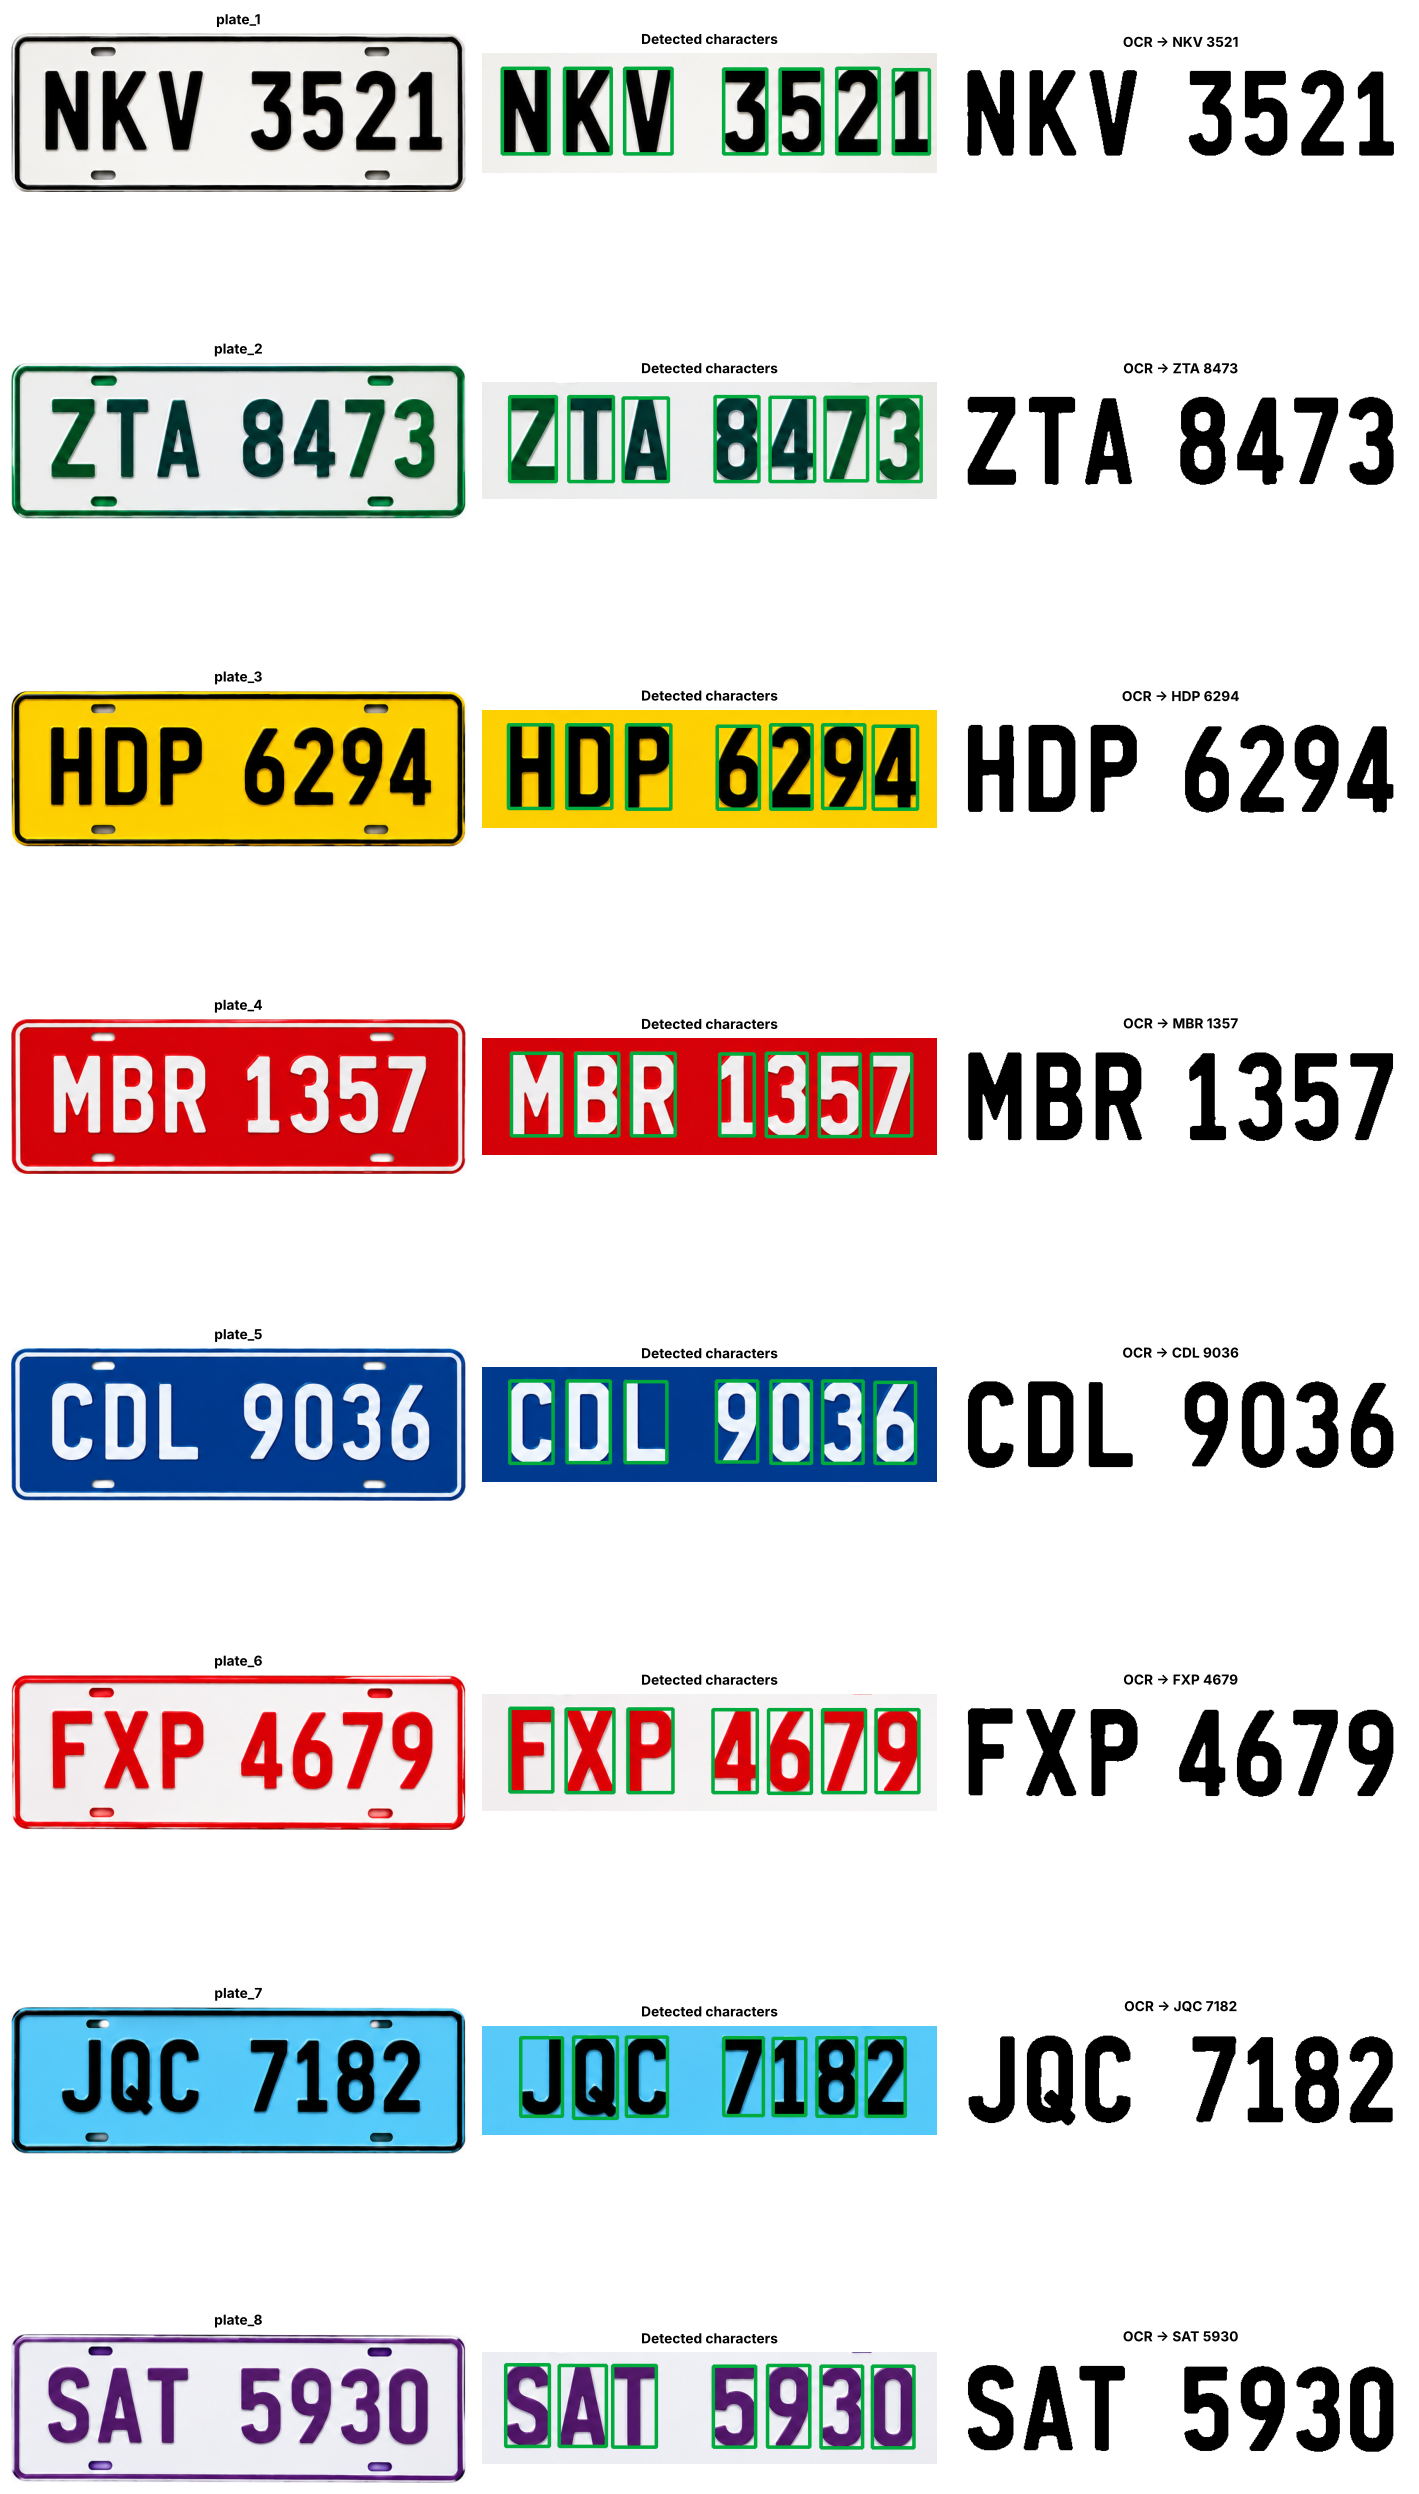

In [6]:
image = cv2.imread(str(IMAGE_PATH))
plates = detect_plates(image)
print(f"{len(plates)} plate(s) found")

results = [recognize_plate(crop, box, i) for i, (crop, box) in enumerate(plates)]

fig, axes = plt.subplots(len(results), 3, figsize=(13, 3.1 * len(results)), squeeze=False)
for row, r in zip(axes, results):
    annotated = cv2.cvtColor(r['crop'], cv2.COLOR_BGR2RGB)
    for x, y, w, h in r['boxes']:
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 170, 60), 3)

    row[0].imshow(cv2.cvtColor(r['image'], cv2.COLOR_BGR2RGB)); row[0].set_title(r['file'], fontsize=9)
    row[1].imshow(annotated); row[1].set_title('Detected characters', fontsize=9)
    row[2].imshow(r['ocr_input'], cmap='gray'); row[2].set_title(f"OCR \u2192 {r['plate']}", fontsize=9)
    for ax in row:
        ax.axis('off')
plt.tight_layout()
plt.show()


Final results.

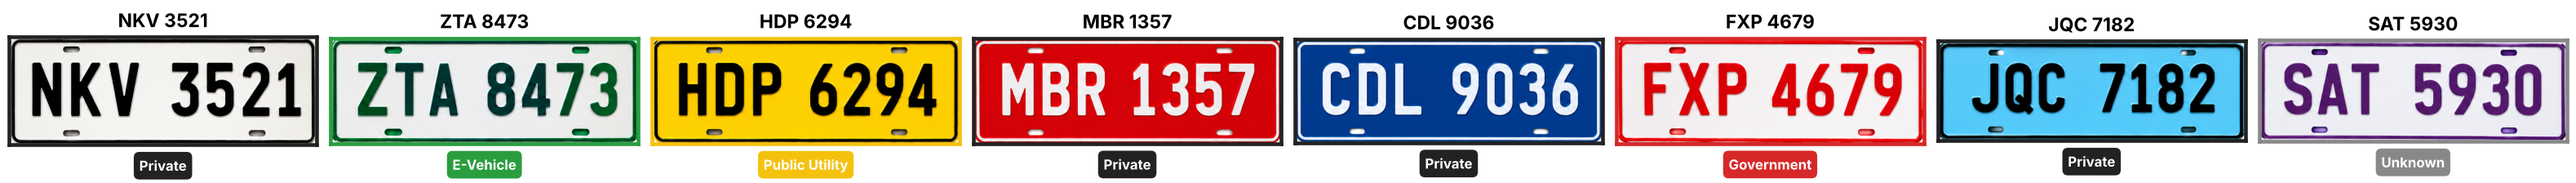

File,Plate number,Category,Background,Characters
plate_1,NKV 3521,Private,white,black
plate_2,ZTA 8473,E-Vehicle,white,green
plate_3,HDP 6294,Public Utility,yellow,black
plate_4,MBR 1357,Private,colored,black
plate_5,CDL 9036,Private,colored,black
plate_6,FXP 4679,Government,white,red
plate_7,JQC 7182,Private,colored,black
plate_8,SAT 5930,Unknown,white,unknown


In [7]:
CATEGORY_COLOR = {'Government': '#d62828', 'E-Vehicle': '#2a9d3f', 'Public Utility': '#f4c20d',
                   'Diplomatic': '#1d4fb8', 'Private': '#222222', 'Unknown': '#888888'}

fig, axes = plt.subplots(1, len(results), figsize=(3.6 * len(results), 3.3))
for ax, r in zip(np.atleast_1d(axes), results):
    color = CATEGORY_COLOR.get(r['category'], '#888888')
    ax.imshow(cv2.cvtColor(r['image'], cv2.COLOR_BGR2RGB))
    ax.set_title(r['plate'], fontsize=15, pad=8)
    ax.set_xlabel(r['category'], fontsize=11, fontweight='bold', color='white',
                  bbox=dict(boxstyle='round,pad=0.4', fc=color, ec='none'), labelpad=10)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(3)
plt.tight_layout()
plt.show()

summary = pd.DataFrame([{'File': r['file'], 'Plate number': r['plate'], 'Category': r['category'],
                          'Background': r.get('background', '-'), 'Characters': r.get('characters', '-')}
                         for r in results])
summary.style.hide(axis='index').set_properties(**{'text-align': 'left'})
